# 2026 DL Lab4: Semantic Segmentation on CIHP

Before we start, please put **your name** and **SID** in following format: <br>
Hi I'm 陸仁賈, 314831000.

**Your Answer:**    
Hi I'm 黃毓峰, 315834011.

## Overview

- Semantic segmentation assigns a semantic class to every pixel in an image.
- In this assignment, predict **20 CIHP classes**: background, clothing and human body parts.
- Implement the original **U-Net from scratch**, using RGB images and semantic category masks.
- Images and masks are already prepared at **320 x 320**, preserving aspect ratio.
  Mask value **255** is an ignored pixel, including padded borders; it is not a 21st class.
- Complete the marked exercises: augmentation, U-Net, pixel accuracy, mIoU, Dice loss and training.
  See `ASSIGNMENT_README.md` and `DATASET_README.md` for the course protocol.

## Kaggle Competition

The TA will announce the **2026 competition link and grading thresholds** separately.
Use the course test images and export `output.csv` with columns `index,pred_mask`.
The reference course score is the mean of per-image mIoU values, including background,
and excluding pixels whose ground-truth value is 255. It is not the official CIHP benchmark score.
Train from scratch using the supplied training set; use validation data for model selection.

## Unzip Data

On Colab the next cell mounts Google Drive and unpacks the five zips from `DRIVE_DIR/data`; elsewhere the prepared `data/` folder beside this notebook is used.

Place this notebook beside the prepared `data/` folder. Data are already prepared on the TA's machine.

- `data/train/`: 28,280 RGB training PNGs
- `data/train_mask/`: corresponding semantic masks
- `data/val/`: 1,000 RGB validation PNGs
- `data/val_mask/`: corresponding semantic masks
- `data/test/`: 3,961 RGB course-test PNGs
- `data/test_index.csv`: fixed mapping between submission index and test filename

Each image/mask is 320 x 320. Masks contain class IDs 0--19 and ignore value 255.
Test answers are kept by the TA. This course test split comes from labeled official validation data;
the official unlabeled CIHP test split is not used here.

In [1]:
# Colab only: mount Google Drive, unpack the data zips kept there and keep checkpoints there (a no-op elsewhere).
import importlib.util
import os
import shutil
import zipfile
from pathlib import Path

ON_COLAB = importlib.util.find_spec("google.colab") is not None
DRIVE_DIR = Path("/content/drive/MyDrive/Colab Notebooks/nycu/deep-learning/lab-4-image-segment")  # DRIVE_DIR/data holds train.zip, train_mask.zip, val.zip, val_mask.zip, test.zip, test_index.csv
EXPECTED_COUNTS = {"train": 28280, "train_mask": 28280, "val": 1000, "val_mask": 1000, "test": 3961}

if ON_COLAB:
    if not Path("/content/drive/MyDrive").is_dir():
        from google.colab import drive
        drive.mount("/content/drive")
    if importlib.util.find_spec("albumentations") is None:
        import subprocess
        import sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "albumentations"], check=True)
    data = Path.cwd() / "data"
    for folder, count in EXPECTED_COUNTS.items():
        target = data / folder
        if target.is_dir() and sum(1 for _ in target.glob("*.png")) == count:
            continue
        archive = DRIVE_DIR / "data" / f"{folder}.zip"
        if not archive.is_file():
            raise FileNotFoundError(f"{archive} is missing: download {folder}.zip from the Kaggle Data page into {archive.parent}")
        target.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as z:
            for member in z.infolist():
                if member.is_dir() or not member.filename.endswith(".png"):
                    continue
                member.filename = Path(member.filename).name  # the zips may carry a leading folder; the data layout is flat
                z.extract(member, target)
        n = sum(1 for _ in target.glob("*.png"))
        print(f"{folder}: {n} PNGs extracted from {archive.name}")
        assert n == count, f"{folder}: expected {count} PNGs, found {n}"
    if not (data / "test_index.csv").is_file():
        shutil.copy(DRIVE_DIR / "data" / "test_index.csv", data / "test_index.csv")
    runs = DRIVE_DIR / "runs"
    runs.mkdir(parents=True, exist_ok=True)
    os.environ["LAB4_RUN_DIR"] = str(runs)  # the mini-SAM section writes its resumable checkpoint there
    print("Data ready in", data, "| checkpoints go to", runs)
else:
    print("Not on Colab: the local data/ folder and checkpoints/ are used")

Mounted at /content/drive
train: 28280 PNGs extracted from train.zip
train_mask: 28280 PNGs extracted from train_mask.zip
val: 1000 PNGs extracted from val.zip
val_mask: 1000 PNGs extracted from val_mask.zip
test: 3961 PNGs extracted from test.zip
Data ready in /content/data | checkpoints go to /content/drive/MyDrive/Colab Notebooks/nycu/deep-learning/lab-4-image-segment/runs


# Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import torchvision
import torch.nn.functional as F
from torch.autograd import Variable

from PIL import Image
import cv2
import albumentations as A

import time
import os
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

from pathlib import Path
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Preprocessing

#### Verify that the paths to the image and mask are correct, and plot the position of the mask on the image.

First, the code establishes DataFrames for the paths of training and validation images, including their corresponding mask paths.

Second, it presents the total number of images in both the training and validation sets.

Third, the code loads a sample training image and its associated mask, visually demonstrating the image and the applied mask in a graphical representation.

In [3]:
# Override this path when running from a different location or after moving the data.
DATA_ROOT = Path("/home/pairlab/Jimmy/DL/LAB4/CIHP/data")
if (Path.cwd() / "data/train").is_dir():
    DATA_ROOT = Path.cwd() / "data"
elif (Path.cwd() / "CIHP/data/train").is_dir():
    DATA_ROOT = Path.cwd() / "CIHP/data"
DATA_ROOT = DATA_ROOT.resolve()
for folder in ["train", "train_mask", "val", "val_mask", "test"]:
    if not (DATA_ROOT / folder).is_dir():
        raise FileNotFoundError(f"Set DATA_ROOT to the prepared CIHP data folder: {DATA_ROOT / folder}")

TRAIN_IMAGE_PATH = str(DATA_ROOT / "train") + os.sep
VAL_IMAGE_PATH = str(DATA_ROOT / "val") + os.sep
TRAIN_MASK_PATH = str(DATA_ROOT / "train_mask") + os.sep
VAL_MASK_PATH = str(DATA_ROOT / "val_mask") + os.sep
OUTPUT_DIR = DATA_ROOT.parent / "checkpoints"  # model weights (lab-3 layout)
OUTPUT_DIR.mkdir(exist_ok=True)
CSV_DIR = DATA_ROOT.parent  # output.csv at the lab root
print("Dataset:", DATA_ROOT)

Dataset: /content/data


In [4]:
n_classes = 20
IGNORE_INDEX = 255
IMAGE_SIZE = 320
CLASS_NAMES = ['Background', 'Hat', 'Hair', 'Glove', 'Sunglasses', 'Upper-clothes', 'Dress', 'Coat', 'Socks', 'Pants', 'Torso-skin', 'Scarf', 'Skirt', 'Face', 'Left-arm', 'Right-arm', 'Left-leg', 'Right-leg', 'Left-shoe', 'Right-shoe']

def create_df(IMAGE_PATH):
    name = sorted(path.stem for path in Path(IMAGE_PATH).glob("*.png"))
    if not name:
        raise FileNotFoundError(f"No prepared PNG images in {IMAGE_PATH}")
    return pd.DataFrame({'id': name}, index=np.arange(len(name)))

train_df = create_df(TRAIN_IMAGE_PATH)
val_df = create_df(VAL_IMAGE_PATH)
print('Total Train Images: ', len(train_df))
print('Total Val Images: ', len(val_df))

Total Train Images:  28280
Total Val Images:  1000


In [5]:
X_train = train_df['id'].to_numpy()
X_val = val_df['id'].to_numpy()

Image Size (320, 320, 3)
Mask Size (320, 320)


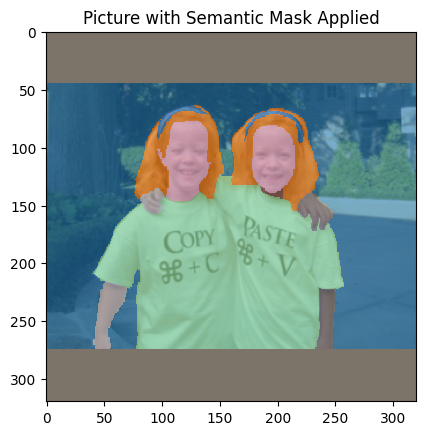

In [6]:
img = Image.open(TRAIN_IMAGE_PATH + train_df['id'][100] + '.png')
mask = np.asarray(Image.open(TRAIN_MASK_PATH + train_df['id'][100] + '.png'))
print('Image Size', np.asarray(img).shape)
print('Mask Size', mask.shape)
plt.imshow(img)
plt.imshow(np.ma.masked_equal(mask, IGNORE_INDEX), alpha=0.6,
           cmap='tab20', vmin=0, vmax=n_classes - 1, interpolation='nearest')
plt.title('Picture with Semantic Mask Applied')
plt.show()

# Loading the Dataset

Define the CIHPDataset for loading the dataset, where each sample comprises an image and its corresponding mask

Build a classs inherit `torch.utils.data.Dataset`.

Implement `__init__`, `__getitem__` and `__len__` 3 functions.  

Some operations could be there: setting location of dataset, the method of reading data, label of dataset or transform of dataset.

See [torch.utils.data.Dataset](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) for more details

The dataset includes a provided, label-aware horizontal flip. It swaps class IDs
14/15, 16/17 and 18/19 after mirroring. Do not add a plain `HorizontalFlip` to the
augmentation pipeline, or the anatomical labels will become inconsistent.

In [7]:
class CIHPDataset(Dataset):

    def __init__(self, img_path, mask_path, X, mean, std, transform=None, hflip_prob=0.0):
        self.img_path = img_path
        self.mask_path = mask_path
        self.X = X
        self.transform = transform
        self.mean = mean
        self.std = std
        self.hflip_prob = hflip_prob
        # Simultaneous lookup avoids overwriting one side before swapping the other.
        self.flip_lut = np.arange(256, dtype=np.uint8)
        self.flip_lut[[14, 15, 16, 17, 18, 19]] = [15, 14, 17, 16, 19, 18]

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        with Image.open(self.img_path + self.X[idx] + '.png') as handle:
            img = np.array(handle.convert('RGB'))
        with Image.open(self.mask_path + self.X[idx] + '.png') as handle:
            mask = np.array(handle, dtype=np.uint8)

        if random.random() < self.hflip_prob:
            img = np.ascontiguousarray(img[:, ::-1])
            mask = np.ascontiguousarray(self.flip_lut[mask[:, ::-1]])

        if self.transform is not None:
            aug = self.transform(image=img, mask=mask)
            img, mask = aug['image'], aug['mask']

        t = T.Compose([T.ToTensor(), T.Normalize(self.mean, self.std)])
        img = t(Image.fromarray(img))
        mask = torch.from_numpy(np.ascontiguousarray(mask)).long()
        return img, mask

## Data augmentation

Use `albumentations.Compose` to transform each image and its mask together.
Photometric operations such as brightness/contrast changes affect only RGB images.
The Dataset already normalizes the image and provides correct horizontal flipping for training.
Do not add `HorizontalFlip`, `Normalize` or `ToTensorV2` here.
If adding spatial transforms, use nearest-neighbor interpolation for masks and fill new mask
pixels with 255; keep output size 320 x 320 and at least one valid pixel per sample.
Validation and test preprocessing must be deterministic; `A.Compose([])` is sufficient.

In [8]:
mean=[0.485, 0.456, 0.406]
std=[0.229, 0.224, 0.225]

# For TRAIN
########################################################################
#  TODO: use albumentations for paired image/mask augmentation        #
#  This one is for training, find the composition to get better result #
########################################################################
PAD_COLOR: tuple[int, int, int] = (124, 116, 104)  # grey border of the prepared images (= ImageNet mean)

transforms_train = A.Compose([
    A.Affine(
        scale=(0.7, 1.3),
        translate_percent=(-0.1, 0.1),
        rotate=(-10, 10),
        interpolation=cv2.INTER_LINEAR,
        mask_interpolation=cv2.INTER_NEAREST,
        border_mode=cv2.BORDER_CONSTANT,
        fill=PAD_COLOR,
        fill_mask=IGNORE_INDEX,
        p=0.7,
    ),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(
        hue_shift_limit=10,
        sat_shift_limit=20,
        val_shift_limit=10,
        p=0.5,
    ),
])
########################################################################
#                           End of your code                           #
########################################################################


# For VAL
########################################################################
#  For validation/test we avoid strong augmentations that change labels #
########################################################################
transforms_val = A.Compose([])
########################################################################
#                           End of your code                           #
########################################################################


#datasets
train_set = CIHPDataset(TRAIN_IMAGE_PATH, TRAIN_MASK_PATH, X_train, mean, std, transforms_train, hflip_prob=0.5)
val_set = CIHPDataset(VAL_IMAGE_PATH, VAL_MASK_PATH, X_val, mean, std, transforms_val)

#dataloader
batch_size = 16
num_workers = 8

train_loader = DataLoader(
    dataset=train_set,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True,
    persistent_workers=True,
    drop_last=True,
)
val_loader = DataLoader(
    dataset=val_set,
    batch_size=1,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
)

In [9]:
train_set[0]

(tensor([[[-0.3027, -0.3027, -0.3027,  ..., -0.3027, -0.3027, -0.3027],
          [-0.3027, -0.3027, -0.3027,  ..., -0.3027, -0.3027, -0.3027],
          [-0.3027, -0.3027, -0.3027,  ..., -0.3027, -0.3027, -0.3027],
          ...,
          [-0.3027, -0.3027, -0.3027,  ..., -0.3027, -0.3027, -0.3027],
          [-0.3027, -0.3027, -0.3027,  ..., -0.3027, -0.3027, -0.3027],
          [-0.3027, -0.3027, -0.3027,  ..., -0.3027, -0.3027, -0.3027]],
 
         [[-0.3901, -0.3901, -0.3901,  ..., -0.3901, -0.3901, -0.3901],
          [-0.3901, -0.3901, -0.3901,  ..., -0.3901, -0.3901, -0.3901],
          [-0.3901, -0.3901, -0.3901,  ..., -0.3901, -0.3901, -0.3901],
          ...,
          [-0.3901, -0.3901, -0.3901,  ..., -0.3901, -0.3901, -0.3901],
          [-0.3901, -0.3901, -0.3901,  ..., -0.3901, -0.3901, -0.3901],
          [-0.3901, -0.3901, -0.3901,  ..., -0.3901, -0.3901, -0.3901]],
 
         [[-0.2881, -0.2881, -0.2881,  ..., -0.2881, -0.2881, -0.2881],
          [-0.2881, -0.2881,

# U-net

U-net is a fully convolution neural network for image semantic segmentation. Consist of encoder and decoder parts connected with skip connections. Encoder extract features of different spatial resolution (skip connections) which are used by decoder to define accurate segmentation mask. Use concatenation for fusing decoder blocks with skip connections.


![image](https://hackmd.io/_uploads/rJXtsY_Up.png)

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    """
    Block with two convolutional blocks
    """

    def __init__(self, in_channels, out_channels, mid_channels=None):
        """
        Double convolution

        :param in_channels: number of in channels for first conv layer
        :param out_channels: number of out channels for last conv layer
        :param mid_channels: number of out channels for first conv layer
        """
        super().__init__()
        if not mid_channels:
            mid_channels = out_channels
        ########################################################################
        #  TODO:                                                               #
        #  write model that contains 2 conv layer with batch normalization     #
        #  and relu activation function                                        #
        ########################################################################

        self.double_conv = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=mid_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(num_features=mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                in_channels=mid_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(num_features=out_channels),
            nn.ReLU(inplace=True),
        )
        ########################################################################
        #                           End of your code                           #
        ########################################################################

    def forward(self, x):
        return self.double_conv(x)


class Down(nn.Module):
    """
    Block for down path
    """

    def __init__(self, in_channels, out_channels):
        """
        Down block

        :param in_channels: number of in channels for double conv block
        :param out_channels: number of out channels for double conv block
        """
        super().__init__()
        ########################################################################
        #  TODO:                                                               #
        #  write model which contains pooling and double conv block            #
        ########################################################################
        self.maxpool_conv = nn.Sequential(
            nn.MaxPool2d(kernel_size=2),
            DoubleConv(in_channels=in_channels, out_channels=out_channels),
        )
        ########################################################################
        #                           End of your code                           #
        ########################################################################

    def forward(self, x):
        return self.maxpool_conv(x)


class Up(nn.Module):
    """
    Block for up path
    """

    def __init__(self, in_channels, out_channels):
        """
        Down block

        :param in_channels: number of in channels for transpose convolution
        :param out_channels: number of out channels for double conv block
        """
        super().__init__()

        self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x1, x2):

        #########################################################################################
        # TODO:                                                                                 #
        # 1. Up-sample the input tensor using transpose convolution                             #
        # 2. Calculate the difference in height and width between x2 and the up-sampled x1      #
        # 3. Pad the up-sampled x1 to match the size of x2                                      #
        # 4. Concatenate x2 and the up-sampled x1 along the channel dimension                   #
        #########################################################################################
        x1 = self.up(x1)
        diffY = x2.size(2) - x1.size(2)
        diffX = x2.size(3) - x1.size(3)
        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2, diffY // 2, diffY - diffY // 2])
        x = torch.cat([x2, x1], dim=1)
        #########################################################################################
        #                           End of your code                                            #
        #########################################################################################


        return self.conv(x)

class OutConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        """
        Final convolution block

        :param in_channels: number of in channels for conv layer
        :param out_channels: number of out channels for conv layer
        """
        super(OutConv, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1)

    def forward(self, x):
        return self.conv(x)

In [11]:
class UNet(nn.Module):
    """UNet model"""
    def __init__(self, n_channels, n_classes):
        super(UNet, self).__init__()
        self.n_channels = n_channels
        self.n_classes = n_classes

        #############################################################
        #  implement the model according to the UNet architecture   #
        #############################################################
        self.inc = DoubleConv(n_channels, 64)
        self.down1 = Down(in_channels=64, out_channels=128)
        self.down2 = Down(in_channels=128, out_channels=256)
        self.down3 = Down(in_channels=256, out_channels=512)
        self.down4 = Down(in_channels=512, out_channels=1024)
        self.up1 = Up(in_channels=1024, out_channels=512)
        self.up2 = Up(in_channels=512, out_channels=256)
        self.up3 = Up(in_channels=256, out_channels=128)
        self.up4 = Up(in_channels=128, out_channels=64)
        self.outc = OutConv(in_channels=64, out_channels=n_classes)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        logits = self.outc(x)
        return logits
        #############################################################
        #                   End of your code                        #
        #############################################################

In [12]:
model = UNet(n_channels=3, n_classes=n_classes)

In [13]:
model

UNet(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): Down(
    (maxpool_conv): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (double_conv): Sequential(
          (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
          (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
 

# Training

In this section, you will implement some functions in your training loop. There are several crucial functions you need to implement:

- Pixel Accuracy: Pixel Accuracy measures the percentage of correctly predicted pixels out of the total pixels in the image

- mIoU (Mean Intersection over Union): mIoU evaluates the spatial overlap between the predicted and ground truth segmentation masks for multiple classes.

- Dice Loss: Dice Loss quantifies the dissimilarity between the predicted and ground truth masks, emphasizing the agreement between the two masks

Try to use labeled data design and train a segmentor (Unet) from scratch to predict the mask of a multi-person CIHP image.

Exclude all target pixels with value 255 from both losses and metrics.
Keep background (class 0) in the metric. The displayed training mIoU is averaged per batch;
validation uses batch size 1, so its mIoU equals the course's mean per-image mIoU protocol.

In [14]:
def pixel_accuracy(output, mask, ignore_index=IGNORE_INDEX):
    with torch.no_grad():
        valid = mask != ignore_index
        if not valid.any():
            return 0.0
        #############################################################################################################
        # TODO: argmax over classes; compute accuracy only at valid pixels.                                         #
        #############################################################################################################
        pred = output.argmax(dim=1)
        correct = (pred[valid] == mask[valid]).sum()
        accuracy = float(correct.item() / valid.sum().item())
        #############################################################################################################
        #                                      End of your code                                                     #
        #############################################################################################################
    return accuracy

## mIoU

mean Intersection over Union (mIoU), a metric used to evaluate the performance of a segmentation model. It takes predicted masks and ground truth masks as input, computes the IoU for each class, and returns the average IoU across all classes.

![image](https://hackmd.io/_uploads/SkLIbhFL6.png)

Course protocol: ignore ground-truth pixels with value 255. Include classes 0--19.
For each image, average IoU over classes with nonzero union, then average across images.
A false-positive class with no ground-truth pixels still has nonzero union and must count as IoU=0.

In [15]:
def mIoU(pred_mask, mask, smooth=1e-10, n_classes=20, ignore_idx=IGNORE_INDEX):
    """Batch mIoU; with batch size 1 this is the course per-image score."""
    with torch.no_grad():
        preds = pred_mask.argmax(dim=1).reshape(-1)
        mask = mask.reshape(-1)
        valid = mask != ignore_idx
        preds, mask = preds[valid], mask[valid]
        ious = []
        for cls in range(n_classes):
            pred_c = preds == cls
            label_c = mask == cls
            #############################################################################################################
            # TODO: Calculate the intersection and union for the current class.                                         #
            #############################################################################################################
            intersect = (pred_c & label_c).sum()
            union = (pred_c | label_c).sum()
            #############################################################################################################
            #                                      End of your code                                                     #
            #############################################################################################################
            if union.item() == 0:
                continue
            ious.append((intersect + smooth) / (union + smooth))
        return float(torch.stack(ious).mean().item()) if ious else 0.0

## Dice Loss

Dice loss is based on Sørensen-Dice coefficient. It measures the overlap between the predicted and target segmentation masks. Dice loss provides a differentiable and smooth measure of segmentation accuracy.

${DiceLoss}(y, \bar p) = 1 - \cfrac{(2y\bar p + \epsilon)}{(y + \bar p + \epsilon)}$

- $y$ represents the ground truth mask.
- $\bar p$ represents the predicted mask.
- $\epsilon$ is a small constant added for numerical stability.

Apply softmax over classes. Replace ignored target IDs before one-hot encoding, then mask out
ignored positions in both predictions and targets. Sum over batch and spatial dimensions,
and average Dice across all 20 classes, including background. An entirely ignored batch returns zero loss.

In [16]:
class DiceLoss(nn.Module):
    """Multiclass soft Dice loss, with ignored pixels excluded."""

    def __init__(self, ignore_index=IGNORE_INDEX):
        super().__init__()
        self.ignore_index = ignore_index

    def forward(self, inputs, targets, eps=1e-6):
        # inputs: (B, C, H, W); targets: (B, H, W), class IDs or 255.
        #######################################
        # TODO: implement masked soft Dice loss.
        #######################################
        n_classes = inputs.shape[1]
        probs = F.softmax(inputs.float(), dim=1)
        valid = (targets != self.ignore_index).unsqueeze(1).float()  # (B, 1, H, W)
        safe_targets = torch.where(targets == self.ignore_index, torch.zeros_like(targets), targets)
        one_hot = F.one_hot(safe_targets, num_classes=n_classes).permute(0, 3, 1, 2).float()
        probs = probs * valid
        one_hot = one_hot * valid
        intersection = (probs * one_hot).sum(dim=(0, 2, 3))
        cardinality = (probs + one_hot).sum(dim=(0, 2, 3))
        dice = (2.0 * intersection + eps) / (cardinality + eps)  # one value per class
        #######################################
        #          End of your code           #
        #######################################
        return 1.0 - dice.mean()

# Training loop

Call train function in a loop.  
Take a break and wait.

In [17]:
def get_lr(optimizer):
    for param_group in optimizer.param_groups:
        return param_group['lr']

def fit(epochs, model, train_loader, val_loader, criterion1, criterion2, optimizer, scheduler, patch=False):
    torch.cuda.empty_cache()
    train_losses = []
    test_losses = []
    val_iou = []; val_acc = []
    train_iou = []; train_acc = []
    lrs = []
    best_miou = 0.0
    not_improve = 0
    use_amp = device.type == 'cuda' and torch.cuda.is_bf16_supported()

    model.to(device)
    fit_time = time.time()
    for e in range(epochs):
        since = time.time()
        running_loss = 0
        iou_score = 0
        accuracy = 0
        #training loop
        model.train()
        for i, data in enumerate(tqdm(train_loader, desc=f"Train {e+1}/{epochs}")):
            #training phase
            ########################################################################
            # TODO: Forward, backward and optimize                                 #
            # 1. process input through the network                                 #
            # 2. compute the two losses                                            #
            # 3. calculate mIoU and pixel accuracy                                   #
            # 4. propagate gradients back into the network’s parameters            #
            # 5. update the weights of the network                                 #
            # 6. reset gradient                                                    #
            ########################################################################
            image, mask = data

            # Also implement zero_grad(), backward() and optimizer.step() in this block.
            image = image.to(device, non_blocking=True)
            mask = mask.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_amp):
                output = model(image)
            loss = 0.5 * criterion1(output.float(), mask) + 0.5 * criterion2(output, mask)
            iou_score += mIoU(output, mask)
            accuracy += pixel_accuracy(output, mask)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            ########################################################################
            #                           End of your code                           #
            ########################################################################
            #step the learning rate
            lrs.append(get_lr(optimizer))
            scheduler.step()

            running_loss += loss.item()

        else:
            model.eval()
            test_loss = 0
            test_accuracy = 0
            val_iou_score = 0
            #validation loop
            with torch.no_grad():
                for i, data in enumerate(tqdm(val_loader, desc=f"Val {e+1}/{epochs}")):
                    ########################################################################
                    # TODO: Forward pass and validation metrics                           #
                    # 1. process input through the network                                 #
                    # 2. compute the two losses                                            #
                    # 3. calculate mIoU and pixel accuracy                                   #
                    # 4. save this batch's loss into test_loss                             #
                    ########################################################################
                    image, mask = data

                    image = image.to(device, non_blocking=True)
                    mask = mask.to(device, non_blocking=True)
                    with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_amp):
                        output = model(image)
                    val_iou_score += mIoU(output, mask)
                    test_accuracy += pixel_accuracy(output, mask)
                    loss = 0.5 * criterion1(output.float(), mask) + 0.5 * criterion2(output, mask)
                    test_loss += loss.item()
                    ########################################################################
                    #                           End of your code                           #
                    ########################################################################

            #calculatio mean for each batch
            train_losses.append(running_loss/len(train_loader))
            test_losses.append(test_loss/len(val_loader))


            epoch_val_miou = val_iou_score / len(val_loader)
            if epoch_val_miou > best_miou:
                print('Val mIoU improving.. {:.4f} >> {:.4f}'.format(best_miou, epoch_val_miou))
                best_miou = epoch_val_miou
                not_improve = 0
                torch.save(model.state_dict(), OUTPUT_DIR / 'Unet-CIHP-best.pt')
            else:
                not_improve += 1
                print(f'Val mIoU not improving for {not_improve} epochs')

            #iou
            val_iou.append(val_iou_score/len(val_loader))
            train_iou.append(iou_score/len(train_loader))
            train_acc.append(accuracy/len(train_loader))
            val_acc.append(test_accuracy/ len(val_loader))
            print("Epoch:{}/{}..".format(e+1, epochs),
                  "Train Loss: {:.3f}..".format(running_loss/len(train_loader)),
                  "Val Loss: {:.3f}..".format(test_loss/len(val_loader)),
                  "Train mIoU:{:.3f}..".format(iou_score/len(train_loader)),
                  "Val mIoU: {:.3f}..".format(val_iou_score/len(val_loader)),
                  "Train Acc:{:.3f}..".format(accuracy/len(train_loader)),
                  "Val Acc:{:.3f}..".format(test_accuracy/len(val_loader)),
                  "Time: {:.2f}m".format((time.time()-since)/60))

            if not_improve >= 7:
                print('Val mIoU not improving for 7 epochs, Stop Training')
                break

    history = {'train_loss' : train_losses, 'val_loss': test_losses,
               'train_miou' :train_iou, 'val_miou':val_iou,
               'train_acc' :train_acc, 'val_acc':val_acc,
               'lrs': lrs}
    print('Total time: {:.2f} m' .format((time.time()- fit_time)/60))
    return history

In [18]:
################################################################################
#     You can adjust those hyper parameters to loop for max_epochs times       #
################################################################################
max_lr = 1e-3
epoch = 20
weight_decay = 1e-4

criterion1 = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
criterion2 = DiceLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr, weight_decay=weight_decay)
sched = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr, epochs=epoch, steps_per_epoch=len(train_loader))

history = fit(epoch, model, train_loader, val_loader, criterion1, criterion2, optimizer, sched)
################################################################################
#                               End of your code                               #
################################################################################

Val 1/20: 100%|██████████| 1000/1000 [00:04<00:00, 233.83it/s]


Val mIoU improving.. 0.0000 >> 0.2629
Epoch:1/20.. Train Loss: 1.085.. Val Loss: 0.819.. Train mIoU:0.136.. Val mIoU: 0.263.. Train Acc:0.655.. Val Acc:0.750.. Time: 2.60m


Val 2/20: 100%|██████████| 1000/1000 [00:04<00:00, 235.95it/s]


Val mIoU improving.. 0.2629 >> 0.3187
Epoch:2/20.. Train Loss: 0.781.. Val Loss: 0.735.. Train mIoU:0.234.. Val mIoU: 0.319.. Train Acc:0.739.. Val Acc:0.782.. Time: 2.55m


Val 3/20: 100%|██████████| 1000/1000 [00:04<00:00, 235.98it/s]


Val mIoU not improving for 1 epochs
Epoch:3/20.. Train Loss: 0.700.. Val Loss: 0.726.. Train mIoU:0.291.. Val mIoU: 0.315.. Train Acc:0.769.. Val Acc:0.781.. Time: 2.55m


... (30 outputs left out)

Val 19/20: 100%|██████████| 1000/1000 [00:04<00:00, 237.64it/s]


Val mIoU not improving for 1 epochs
Epoch:19/20.. Train Loss: 0.362.. Val Loss: 0.533.. Train mIoU:0.542.. Val mIoU: 0.518.. Train Acc:0.893.. Val Acc:0.879.. Time: 2.55m


Val 20/20: 100%|██████████| 1000/1000 [00:04<00:00, 237.55it/s]

Val mIoU not improving for 2 epochs
Epoch:20/20.. Train Loss: 0.361.. Val Loss: 0.534.. Train mIoU:0.542.. Val mIoU: 0.519.. Train Acc:0.894.. Val Acc:0.879.. Time: 2.55m
Total time: 51.07 m


In [19]:
torch.save(model.state_dict(), OUTPUT_DIR / 'Unet-CIHP-last.pt')

#### Visualize accuracy and loss

In [20]:
def plot_loss(history):
    plt.plot(history['val_loss'], label='val', marker='o')
    plt.plot( history['train_loss'], label='train', marker='o')
    plt.title('Loss per epoch'); plt.ylabel('loss');
    plt.xlabel('epoch')
    plt.legend(), plt.grid()
    plt.show()

def plot_score(history):
    plt.plot(history['train_miou'], label='train_mIoU', marker='*')
    plt.plot(history['val_miou'], label='val_mIoU',  marker='*')
    plt.title('Score per epoch'); plt.ylabel('mean IoU')
    plt.xlabel('epoch')
    plt.legend(), plt.grid()
    plt.show()

def plot_acc(history):
    plt.plot(history['train_acc'], label='train_accuracy', marker='*')
    plt.plot(history['val_acc'], label='val_accuracy',  marker='*')
    plt.title('Accuracy per epoch'); plt.ylabel('Accuracy')
    plt.xlabel('epoch')
    plt.legend(), plt.grid()
    plt.show()

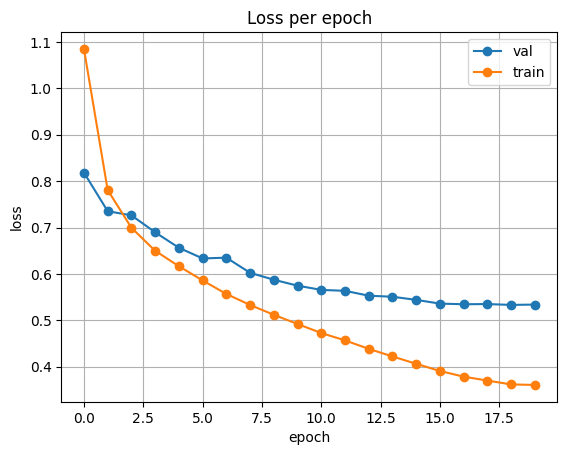

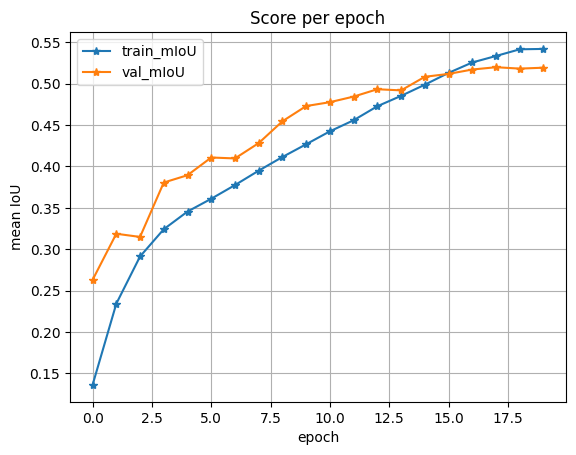

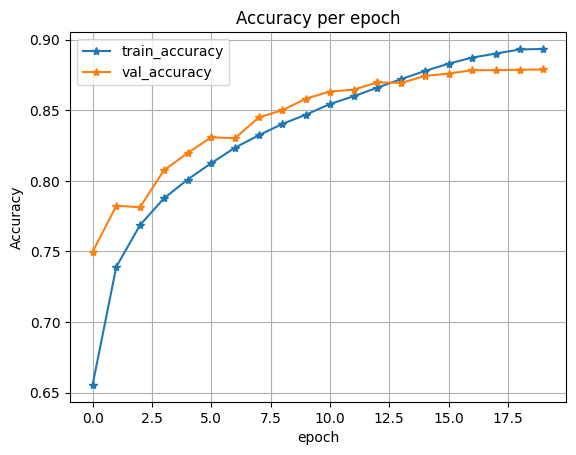

In [21]:
plot_loss(history)
plot_score(history)
plot_acc(history)

# Mini-SAM: the final model

The U-Net above is the required baseline. The model that produces `output.csv` is a small SAM-style segmenter trained
from scratch on the provided training set only (no pretrained weights, no external data, one model, one training run):

- **Encoder**: stride-4 convolutional stem, then a four-stage hierarchical transformer (windowed attention at strides
  4 and 8, global attention at 16 and 32, depthwise-convolution positional encoding, LayerScale, stochastic depth).
- **Neck + decoder**: an FPN neck and a SAM two-way-transformer mask decoder whose 20 learnable class tokens predict
  the class masks at stride 4 (plus an auxiliary stride-8 head during training).
- **Recipe**: loss 0.5 CE + 0.5 Dice + 0.4 auxiliary CE; AdamW, linear warmup then cosine decay, EMA weights,
  bf16 autocast, label-aware horizontal flip and affine augmentation; input 448 x 448
  (the data are 320 x 320); the epoch with the best validation per-image mIoU (the graded metric) is kept.
- **Resumable**: the full training state is written to `LAST_PATH` after every epoch (on Google Drive when run on
  Colab). If the session is reclaimed, run the notebook again from the top: the training cell resumes and replays the
  earlier epoch lines, so its output is the complete record.
- **Time**: about 2.9 min per epoch on an RTX PRO 6000 (Colab G4), about 7.2 h for 150 epochs,
  plus a few minutes for the inference chain and the CSV.

## Imports and constants

In [22]:
import csv
import json
import math
import os
import random
import sys
import time
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import TextIO
import albumentations as A
import cv2
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn, optim
from torch.utils.data import DataLoader, Dataset

N_CLASSES: int = 20
IGNORE_INDEX: int = 255
ORIG_SIZE: int = 320  # resolution of the competition images and masks; cfg.img_size is the training/inference resolution
CLASS_NAMES: list[str] = [
    "Background", "Hat", "Hair", "Glove", "Sunglasses", "Upper-clothes", "Dress", "Coat", "Socks", "Pants",
    "Torso-skin", "Scarf", "Skirt", "Face", "Left-arm", "Right-arm", "Left-leg", "Right-leg", "Left-shoe", "Right-shoe",
]
MEAN: tuple[float, float, float] = (0.485, 0.456, 0.406)
STD: tuple[float, float, float] = (0.229, 0.224, 0.225)
PAD_COLOR: tuple[int, int, int] = (124, 116, 104)  # grey border already present in the prepared images
FLIP_LUT: np.ndarray = np.arange(256, dtype=np.uint8)
FLIP_LUT[[14, 15, 16, 17, 18, 19]] = [15, 14, 17, 16, 19, 18]
FLIP_CHANNEL_PERM: list[int] = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 14, 17, 16, 19, 18]


class Tee:
    """Mirror writes to the console and a log file."""

    def __init__(self, *streams: TextIO) -> None:
        self.streams = streams

    def write(self, text: str) -> None:
        for stream in self.streams:
            stream.write(text)
            stream.flush()

    def flush(self) -> None:
        for stream in self.streams:
            stream.flush()


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

## Configuration and paths

In [23]:
EXPERIMENT_NAME: str = "minisam-final"


@dataclass(frozen=True)
class ExperimentConfig:
    seed: int = 2026
    # data / augmentation
    img_size: int = 448
    scale_range: tuple[float, float] = (0.5, 2.0)
    translate: float = 0.2
    rotate_deg: float = 10.0
    affine_p: float = 0.8
    batch_size: int = 16
    num_workers: int = 16
    # encoder
    stem_dim: int = 48
    dims: tuple[int, ...] = (96, 192, 384, 768)
    depths: tuple[int, ...] = (2, 2, 12, 2)
    heads: tuple[int, ...] = (3, 6, 12, 24)
    windows: tuple[int, ...] = (8, 8, 0, 0)  # 0 = global attention
    stage_types: tuple[str, ...] = ("attn", "attn", "attn", "attn")  # "attn" or "conv" (ConvNeXt block)
    mlp_ratio: float = 4.0
    layer_scale_init: float = 0.1
    drop_path_rate: float = 0.2
    # neck + decoder
    neck_dim: int = 256
    decoder_depth: int = 2
    decoder_heads: int = 8
    decoder_mlp_dim: int = 1024
    mask_dim: int = 64
    aux_weight: float = 0.4
    # loss
    ce_weight: float = 0.5
    dice_weight: float = 0.5
    # optimisation
    epochs: int = 150
    warmup_epochs: int = 5
    lr: float = 6e-4
    min_lr: float = 1e-5
    weight_decay: float = 0.05
    grad_clip: float = 1.0
    ema_decay: float = 0.9995
    tta_hflip: bool = True
    notes: list[str] = field(default_factory=list)


CONFIG = ExperimentConfig()
INFER_SIZES: tuple[int, ...] = (512, 576, 640, 704, 768)  # input sizes averaged at test time (multiples of 64; the decoder's positional embedding is resized)
MIN_AREA: int = 50  # per image, drop any non-background class predicted on fewer pixels than this
SMOKE_SUBSET: int | None = None  # scripts/tools/smoke_final_notebook.py sets this to run on a few images


DATA_DIR: Path = DATA_ROOT
RUN_DIR: Path = Path(os.environ.get("LAB4_RUN_DIR", str(OUTPUT_DIR)))  # on Colab this is on Google Drive, so a reclaimed session resumes
RUN_DIR.mkdir(parents=True, exist_ok=True)
LAST_PATH: Path = RUN_DIR / f"{EXPERIMENT_NAME}-last.pt"  # full training state, rewritten after every epoch
CKPT_PATH: Path = RUN_DIR / f"{EXPERIMENT_NAME}-best.pt"  # weights of the best epoch (by val mIoU), used for the CSV
print("checkpoints:", RUN_DIR)

checkpoints: /content/drive/MyDrive/Colab Notebooks/nycu/deep-learning/lab-4-image-segment/runs


## Data: resized to the training size, label-aware flip, affine augmentation

In [24]:
def list_ids(folder: Path) -> list[str]:
    ids = sorted(p.stem for p in folder.glob("*.png"))
    if not ids:
        raise FileNotFoundError(f"no PNG images in {folder}")
    return ids


class CIHPSegDataset(Dataset):
    """Image + mask pairs; label-aware horizontal flip, then albumentations, then normalise."""

    def __init__(
        self,
        image_dir: Path,
        mask_dir: Path,
        ids: list[str],
        transform: A.Compose | None,
        hflip_prob: float,
        size: int = ORIG_SIZE,
        resize_mask: bool = True,
    ) -> None:
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.ids = ids
        self.transform = transform
        self.hflip_prob = hflip_prob
        self.size = size
        self.resize_mask = resize_mask  # False keeps the mask at ORIG_SIZE so the metric is computed on the original labels
        self.mean = torch.tensor(MEAN).view(3, 1, 1)
        self.std = torch.tensor(STD).view(3, 1, 1)

    def __len__(self) -> int:
        return len(self.ids)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        stem = self.ids[index]
        with Image.open(self.image_dir / f"{stem}.png") as handle:
            image = np.array(handle.convert("RGB"))
        with Image.open(self.mask_dir / f"{stem}.png") as handle:
            mask = np.array(handle, dtype=np.uint8)
        if self.size != image.shape[0]:
            image = cv2.resize(image, (self.size, self.size), interpolation=cv2.INTER_LINEAR)
            if self.resize_mask:
                mask = cv2.resize(mask, (self.size, self.size), interpolation=cv2.INTER_NEAREST)
        if random.random() < self.hflip_prob:
            image = np.ascontiguousarray(image[:, ::-1])
            mask = np.ascontiguousarray(FLIP_LUT[mask[:, ::-1]])
        if self.transform is not None:
            out = self.transform(image=image, mask=mask)
            image, mask = out["image"], out["mask"]
        tensor = torch.from_numpy(np.ascontiguousarray(image)).permute(2, 0, 1).float().div_(255.0)
        tensor = (tensor - self.mean) / self.std
        return tensor, torch.from_numpy(np.ascontiguousarray(mask)).long()


class CIHPTestDataset(Dataset):
    def __init__(self, image_dir: Path, ids: list[str], size: int = ORIG_SIZE) -> None:
        self.image_dir = image_dir
        self.ids = ids
        self.size = size
        self.mean = torch.tensor(MEAN).view(3, 1, 1)
        self.std = torch.tensor(STD).view(3, 1, 1)

    def __len__(self) -> int:
        return len(self.ids)

    def __getitem__(self, index: int) -> torch.Tensor:
        with Image.open(self.image_dir / f"{self.ids[index]}.png") as handle:
            image = np.array(handle.convert("RGB"))
        if self.size != image.shape[0]:
            image = cv2.resize(image, (self.size, self.size), interpolation=cv2.INTER_LINEAR)
        tensor = torch.from_numpy(image).permute(2, 0, 1).float().div_(255.0)
        return (tensor - self.mean) / self.std


def build_train_transform(cfg: ExperimentConfig) -> A.Compose:
    return A.Compose([
        A.Affine(
            scale=cfg.scale_range,
            translate_percent=(-cfg.translate, cfg.translate),
            rotate=(-cfg.rotate_deg, cfg.rotate_deg),
            interpolation=cv2.INTER_LINEAR,
            mask_interpolation=cv2.INTER_NEAREST,
            border_mode=cv2.BORDER_CONSTANT,
            fill=PAD_COLOR,
            fill_mask=IGNORE_INDEX,
            p=cfg.affine_p,
        ),
        A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.5),
        A.HueSaturationValue(
            hue_shift_limit=10,
            sat_shift_limit=25,
            val_shift_limit=10,
            p=0.5,
        ),
    ])

## Model

In [25]:
class DropPath(nn.Module):
    """Stochastic depth per sample."""

    def __init__(self, p: float) -> None:
        super().__init__()
        self.p = p

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.p == 0.0 or not self.training:
            return x
        keep = 1.0 - self.p
        mask = x.new_empty((x.shape[0],) + (1,) * (x.ndim - 1)).bernoulli_(keep)
        return x * mask / keep


class LayerNorm2d(nn.Module):
    """LayerNorm over the channel dim of a (B, C, H, W) tensor, as in SAM."""

    def __init__(self, dim: int, eps: float = 1e-6) -> None:
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.bias = nn.Parameter(torch.zeros(dim))
        self.eps = eps

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.float()
        mean = x.mean(dim=1, keepdim=True)
        var = (x - mean).pow(2).mean(dim=1, keepdim=True)
        x = (x - mean) / torch.sqrt(var + self.eps)
        return x * self.weight[:, None, None] + self.bias[:, None, None]


class Mlp(nn.Module):
    def __init__(self, dim: int, hidden: int) -> None:
        super().__init__()
        self.fc1 = nn.Linear(in_features=dim, out_features=hidden)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(in_features=hidden, out_features=dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc2(self.act(self.fc1(x)))


class WindowAttention(nn.Module):
    """Multi-head self-attention inside non-overlapping windows; window 0 means global."""

    def __init__(self, dim: int, heads: int, window: int) -> None:
        super().__init__()
        assert dim % heads == 0
        self.heads = heads
        self.window = window
        self.qkv = nn.Linear(in_features=dim, out_features=3 * dim)
        self.proj = nn.Linear(in_features=dim, out_features=dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # x: (B, H, W, C)
        b, h, w, c = x.shape
        win = self.window if self.window > 0 else h
        assert h % win == 0 and w % win == 0, f"window {win} must divide {h}x{w}"
        x = x.view(b, h // win, win, w // win, win, c).permute(0, 1, 3, 2, 4, 5).reshape(-1, win * win, c)
        qkv = self.qkv(x).reshape(x.shape[0], win * win, 3, self.heads, c // self.heads).permute(2, 0, 3, 1, 4)
        out = F.scaled_dot_product_attention(qkv[0], qkv[1], qkv[2])
        out = out.transpose(1, 2).reshape(x.shape[0], win * win, c)
        out = self.proj(out)
        return out.view(b, h // win, w // win, win, win, c).permute(0, 1, 3, 2, 4, 5).reshape(b, h, w, c)


class AttnBlock(nn.Module):
    """Depthwise-conv positional encoding + windowed/global attention + MLP, pre-norm with LayerScale."""

    def __init__(
        self,
        dim: int,
        heads: int,
        window: int,
        mlp_ratio: float,
        layer_scale_init: float,
        drop_path: float,
    ) -> None:
        super().__init__()
        self.cpe = nn.Conv2d(in_channels=dim, out_channels=dim, kernel_size=3, padding=1, groups=dim)
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowAttention(dim=dim, heads=heads, window=window)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = Mlp(dim=dim, hidden=int(dim * mlp_ratio))
        self.ls1 = nn.Parameter(layer_scale_init * torch.ones(dim))
        self.ls2 = nn.Parameter(layer_scale_init * torch.ones(dim))
        self.drop_path = DropPath(p=drop_path)

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # (B, H, W, C)
        x = x + self.cpe(x.permute(0, 3, 1, 2)).permute(0, 2, 3, 1)
        x = x + self.drop_path(self.ls1 * self.attn(self.norm1(x)))
        x = x + self.drop_path(self.ls2 * self.mlp(self.norm2(x)))
        return x


class ConvBlock(nn.Module):
    """ConvNeXt block (7x7 depthwise conv, LayerNorm, MLP), the convolutional fallback for early stages."""

    def __init__(self, dim: int, mlp_ratio: float, layer_scale_init: float, drop_path: float) -> None:
        super().__init__()
        self.dwconv = nn.Conv2d(in_channels=dim, out_channels=dim, kernel_size=7, padding=3, groups=dim)
        self.norm = nn.LayerNorm(dim)
        self.mlp = Mlp(dim=dim, hidden=int(dim * mlp_ratio))
        self.ls = nn.Parameter(layer_scale_init * torch.ones(dim))
        self.drop_path = DropPath(p=drop_path)

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # (B, H, W, C)
        y = self.dwconv(x.permute(0, 3, 1, 2)).permute(0, 2, 3, 1)
        y = self.mlp(self.norm(y))
        return x + self.drop_path(self.ls * y)


class Downsample(nn.Module):
    """Hiera-style stage transition: 2x2 max-pool of the tokens, then a linear projection."""

    def __init__(self, dim_in: int, dim_out: int) -> None:
        super().__init__()
        self.proj = nn.Linear(in_features=dim_in, out_features=dim_out)

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # (B, H, W, C)
        x = F.max_pool2d(x.permute(0, 3, 1, 2), kernel_size=2).permute(0, 2, 3, 1)
        return self.proj(x)


class ConvStem(nn.Module):
    """Three 3x3 convolutions to stride 4 ('early convolutions help transformers see better')."""

    def __init__(self, stem_dim: int, out_dim: int) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=stem_dim, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(num_features=stem_dim),
            nn.GELU(),
            nn.Conv2d(in_channels=stem_dim, out_channels=stem_dim * 2, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(num_features=stem_dim * 2),
            nn.GELU(),
            nn.Conv2d(in_channels=stem_dim * 2, out_channels=out_dim, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(num_features=out_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # (B, 3, H, W) -> (B, H/4, W/4, C)
        return self.net(x).permute(0, 2, 3, 1)


class HierarchicalEncoder(nn.Module):
    """Four stages at strides 4/8/16/32; returns channels-first feature maps of every stage."""

    def __init__(self, cfg: ExperimentConfig) -> None:
        super().__init__()
        self.stem = ConvStem(stem_dim=cfg.stem_dim, out_dim=cfg.dims[0])
        total_blocks = sum(cfg.depths)
        drop_rates = [cfg.drop_path_rate * i / max(total_blocks - 1, 1) for i in range(total_blocks)]
        self.stages = nn.ModuleList()
        self.downsamples = nn.ModuleList()
        block_index = 0
        for stage, (dim, depth, heads, window, kind) in enumerate(
            zip(cfg.dims, cfg.depths, cfg.heads, cfg.windows, cfg.stage_types)
        ):
            blocks: list[nn.Module] = []
            for _ in range(depth):
                if kind == "attn":
                    blocks.append(AttnBlock(
                        dim=dim,
                        heads=heads,
                        window=window,
                        mlp_ratio=cfg.mlp_ratio,
                        layer_scale_init=cfg.layer_scale_init,
                        drop_path=drop_rates[block_index],
                    ))
                elif kind == "conv":
                    blocks.append(ConvBlock(
                        dim=dim,
                        mlp_ratio=cfg.mlp_ratio,
                        layer_scale_init=cfg.layer_scale_init,
                        drop_path=drop_rates[block_index],
                    ))
                else:
                    raise ValueError(kind)
                block_index += 1
            self.stages.append(nn.Sequential(*blocks))
            if stage + 1 < len(cfg.dims):
                self.downsamples.append(Downsample(dim_in=dim, dim_out=cfg.dims[stage + 1]))
        self.norms = nn.ModuleList(nn.LayerNorm(dim) for dim in cfg.dims)

    def forward(self, x: torch.Tensor) -> list[torch.Tensor]:
        x = self.stem(x)
        features: list[torch.Tensor] = []
        for stage, blocks in enumerate(self.stages):
            x = blocks(x)
            features.append(self.norms[stage](x).permute(0, 3, 1, 2).contiguous())
            if stage < len(self.downsamples):
                x = self.downsamples[stage](x)
        return features


class FPNNeck(nn.Module):
    """SAM 2-style neck: 1x1 laterals to a common width, top-down nearest-upsample adds, 3x3 smoothing."""

    def __init__(self, in_dims: tuple[int, ...], dim: int) -> None:
        super().__init__()
        self.laterals = nn.ModuleList(
            nn.Sequential(nn.Conv2d(in_channels=d, out_channels=dim, kernel_size=1, bias=False), nn.BatchNorm2d(num_features=dim))
            for d in in_dims
        )
        self.smooth = nn.ModuleList(
            nn.Sequential(
                nn.Conv2d(in_channels=dim, out_channels=dim, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(num_features=dim),
                nn.GELU(),
            )
            for _ in in_dims
        )

    def forward(self, features: list[torch.Tensor]) -> list[torch.Tensor]:
        laterals = [lateral(f) for lateral, f in zip(self.laterals, features)]
        for level in range(len(laterals) - 1, 0, -1):
            laterals[level - 1] = laterals[level - 1] + F.interpolate(laterals[level], scale_factor=2.0, mode="nearest")
        return [smooth(l) for smooth, l in zip(self.smooth, laterals)]


class CrossAttention(nn.Module):
    """Attention with an optional internal down-projection, as in SAM's two-way transformer."""

    def __init__(self, dim: int, heads: int, downsample_rate: int = 1) -> None:
        super().__init__()
        inner = dim // downsample_rate
        assert inner % heads == 0
        self.heads = heads
        self.q_proj = nn.Linear(in_features=dim, out_features=inner)
        self.k_proj = nn.Linear(in_features=dim, out_features=inner)
        self.v_proj = nn.Linear(in_features=dim, out_features=inner)
        self.out_proj = nn.Linear(in_features=inner, out_features=dim)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor) -> torch.Tensor:
        b, nq, _ = q.shape
        nk = k.shape[1]
        q = self.q_proj(q).view(b, nq, self.heads, -1).transpose(1, 2)
        k = self.k_proj(k).view(b, nk, self.heads, -1).transpose(1, 2)
        v = self.v_proj(v).view(b, nk, self.heads, -1).transpose(1, 2)
        out = F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(b, nq, -1)
        return self.out_proj(out)


class TwoWayBlock(nn.Module):
    """SAM decoder block: token self-attn, token->image cross-attn, token MLP, image->token cross-attn."""

    def __init__(self, dim: int, heads: int, mlp_dim: int) -> None:
        super().__init__()
        self.self_attn = CrossAttention(dim=dim, heads=heads)
        self.norm1 = nn.LayerNorm(dim)
        self.cross_t2i = CrossAttention(dim=dim, heads=heads, downsample_rate=2)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = Mlp(dim=dim, hidden=mlp_dim)
        self.norm3 = nn.LayerNorm(dim)
        self.cross_i2t = CrossAttention(dim=dim, heads=heads, downsample_rate=2)
        self.norm4 = nn.LayerNorm(dim)

    def forward(
        self,
        queries: torch.Tensor,
        keys: torch.Tensor,
        query_pe: torch.Tensor,
        key_pe: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        q = queries + query_pe
        queries = self.norm1(queries + self.self_attn(q=q, k=q, v=queries))
        q = queries + query_pe
        k = keys + key_pe
        queries = self.norm2(queries + self.cross_t2i(q=q, k=k, v=keys))
        queries = self.norm3(queries + self.mlp(queries))
        q = queries + query_pe
        k = keys + key_pe
        keys = self.norm4(keys + self.cross_i2t(q=k, k=q, v=queries))
        return queries, keys


class MaskDecoder(nn.Module):
    """Two-way transformer over 20 class tokens and the stride-16 embedding; masks = tokens . pixel embedding."""

    def __init__(self, cfg: ExperimentConfig, grid: int) -> None:
        super().__init__()
        dim = cfg.neck_dim
        self.class_tokens = nn.Parameter(torch.zeros(1, N_CLASSES, dim))
        self.image_pe = nn.Parameter(torch.zeros(1, grid * grid, dim))
        nn.init.trunc_normal_(self.class_tokens, std=0.02)
        nn.init.trunc_normal_(self.image_pe, std=0.02)
        self.blocks = nn.ModuleList(
            TwoWayBlock(dim=dim, heads=cfg.decoder_heads, mlp_dim=cfg.decoder_mlp_dim) for _ in range(cfg.decoder_depth)
        )
        self.final_attn = CrossAttention(dim=dim, heads=cfg.decoder_heads, downsample_rate=2)
        self.final_norm = nn.LayerNorm(dim)
        # upscaling path stride 16 -> 8 -> 4, fed with the FPN high-resolution features as in SAM 2
        self.up1 = nn.ConvTranspose2d(in_channels=dim, out_channels=dim // 2, kernel_size=2, stride=2)
        self.skip8 = nn.Conv2d(in_channels=dim, out_channels=dim // 2, kernel_size=1)
        self.norm_up1 = LayerNorm2d(dim // 2)
        self.up2 = nn.ConvTranspose2d(in_channels=dim // 2, out_channels=cfg.mask_dim, kernel_size=2, stride=2)
        self.skip4 = nn.Conv2d(in_channels=dim, out_channels=cfg.mask_dim, kernel_size=1)
        self.act = nn.GELU()
        self.hypernet = nn.Sequential(
            nn.Linear(in_features=dim, out_features=dim),
            nn.GELU(),
            nn.Linear(in_features=dim, out_features=dim),
            nn.GELU(),
            nn.Linear(in_features=dim, out_features=cfg.mask_dim),
        )

    def forward(self, feat4: torch.Tensor, feat8: torch.Tensor, feat16: torch.Tensor) -> torch.Tensor:
        b, c, h, w = feat16.shape
        keys = feat16.flatten(2).transpose(1, 2)  # (B, HW, C)
        queries = self.class_tokens.expand(b, -1, -1)
        query_pe = torch.zeros_like(queries)
        key_pe = self.image_pe.expand(b, -1, -1)
        for block in self.blocks:
            queries, keys = block(queries=queries, keys=keys, query_pe=query_pe, key_pe=key_pe)
        q = queries + query_pe
        k = keys + key_pe
        queries = self.final_norm(queries + self.final_attn(q=q, k=k, v=keys))
        image = keys.transpose(1, 2).reshape(b, c, h, w)
        image = self.act(self.norm_up1(self.up1(image) + self.skip8(feat8)))
        pixel = self.act(self.up2(image) + self.skip4(feat4))  # (B, mask_dim, H/4, W/4)
        mask_embed = self.hypernet(queries)  # (B, 20, mask_dim)
        return torch.einsum("bqc,bchw->bqhw", mask_embed, pixel)


class MiniSAM(nn.Module):
    def __init__(self, cfg: ExperimentConfig) -> None:
        super().__init__()
        self.encoder = HierarchicalEncoder(cfg=cfg)
        self.neck = FPNNeck(in_dims=cfg.dims, dim=cfg.neck_dim)
        self.decoder = MaskDecoder(cfg=cfg, grid=cfg.img_size // 16)
        self.aux_head = nn.Conv2d(in_channels=cfg.neck_dim, out_channels=N_CLASSES, kernel_size=1)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module: nn.Module) -> None:
        if isinstance(module, nn.Linear):
            nn.init.trunc_normal_(module.weight, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
            if module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor | None]:
        size = x.shape[-2:]
        feats = self.neck(self.encoder(x))
        logits = self.decoder(feat4=feats[0], feat8=feats[1], feat16=feats[2])
        logits = F.interpolate(logits, size=size, mode="bilinear", align_corners=False)
        if not self.training:
            return logits, None
        aux = F.interpolate(self.aux_head(feats[0]), size=size, mode="bilinear", align_corners=False)
        return logits, aux

## Loss and metrics (per-image mIoU, the course protocol)

In [26]:
def dice_loss(logits: torch.Tensor, targets: torch.Tensor, eps: float = 1e-6) -> torch.Tensor:
    probs = F.softmax(logits.float(), dim=1)
    valid = (targets != IGNORE_INDEX).unsqueeze(1).float()
    safe = torch.where(targets == IGNORE_INDEX, torch.zeros_like(targets), targets)
    one_hot = F.one_hot(safe, num_classes=N_CLASSES).permute(0, 3, 1, 2).float()
    probs = probs * valid
    one_hot = one_hot * valid
    intersection = (probs * one_hot).sum(dim=(0, 2, 3))
    cardinality = (probs + one_hot).sum(dim=(0, 2, 3))
    return 1.0 - ((2.0 * intersection + eps) / (cardinality + eps)).mean()


def seg_loss(logits: torch.Tensor, targets: torch.Tensor, cfg: ExperimentConfig) -> torch.Tensor:
    ce = F.cross_entropy(logits.float(), targets, ignore_index=IGNORE_INDEX)
    return cfg.ce_weight * ce + cfg.dice_weight * dice_loss(logits=logits, targets=targets)


def confusion_per_image(pred: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    """(B, H, W) predictions and targets -> (B, 20, 20) confusion matrices, ignoring 255."""
    valid = target != IGNORE_INDEX
    index = target.clamp(max=N_CLASSES - 1) * N_CLASSES + pred
    index = torch.where(valid, index, torch.full_like(index, N_CLASSES * N_CLASSES))
    counts = torch.stack([torch.bincount(row.flatten(), minlength=N_CLASSES * N_CLASSES + 1) for row in index])
    return counts[:, : N_CLASSES * N_CLASSES].view(-1, N_CLASSES, N_CLASSES)


def miou_from_confusion(conf: torch.Tensor) -> torch.Tensor:
    """Per-image mIoU (course protocol) from (B, 20, 20) confusion matrices."""
    inter = conf.diagonal(dim1=1, dim2=2).float()
    union = conf.sum(dim=1).float() + conf.sum(dim=2).float() - inter
    present = union > 0
    iou = torch.where(present, inter / union.clamp(min=1), torch.zeros_like(inter))
    return iou.sum(dim=1) / present.sum(dim=1).clamp(min=1)


@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    device: torch.device,
    cfg: ExperimentConfig,
    tta_hflip: bool = False,
) -> tuple[float, float, float, torch.Tensor]:
    """Returns (mean per-image mIoU, pixel accuracy, mean loss, global per-class IoU)."""
    model.eval()
    mious: list[torch.Tensor] = []
    total_conf = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=device)
    loss_sum = 0.0
    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        logits = predict_logits(model=model, images=images, tta_hflip=tta_hflip)
        if logits.shape[-2:] != masks.shape[-2:]:
            logits = F.interpolate(logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)
        loss_sum += seg_loss(logits=logits, targets=masks, cfg=cfg).item() * images.shape[0]
        conf = confusion_per_image(pred=logits.argmax(dim=1), target=masks)
        mious.append(miou_from_confusion(conf=conf))
        total_conf += conf.sum(dim=0)
    miou_all = torch.cat(mious)
    inter = total_conf.diagonal().float()
    union = total_conf.sum(dim=0).float() + total_conf.sum(dim=1).float() - inter
    per_class = inter / union.clamp(min=1)
    pixel_acc = (inter.sum() / total_conf.sum().clamp(min=1)).item()
    return miou_all.mean().item(), pixel_acc, loss_sum / len(loader.dataset), per_class.cpu()


def predict_logits(model: nn.Module, images: torch.Tensor, tta_hflip: bool) -> torch.Tensor:
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        logits, _ = model(images)
        logits = logits.float()
        if tta_hflip:
            flipped, _ = model(images.flip(dims=[3]))
            flipped = flipped.float().flip(dims=[3])[:, FLIP_CHANNEL_PERM]
            logits = 0.5 * (logits + flipped)
    return logits

## Optimisation: parameter groups, warmup + cosine schedule, EMA

In [27]:
def param_groups(model: nn.Module, weight_decay: float) -> list[dict]:
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if param.ndim <= 1 or name.endswith(".ls") or ".ls1" in name or ".ls2" in name or "tokens" in name or "_pe" in name:
            no_decay.append(param)
        else:
            decay.append(param)
    return [{"params": decay, "weight_decay": weight_decay}, {"params": no_decay, "weight_decay": 0.0}]


def lr_at(step: int, total_steps: int, warmup_steps: int, cfg: ExperimentConfig) -> float:
    if step < warmup_steps:
        return cfg.lr * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(total_steps - warmup_steps, 1)
    return cfg.min_lr + 0.5 * (cfg.lr - cfg.min_lr) * (1.0 + math.cos(math.pi * progress))


class EMA:
    """Exponential moving average of the parameters and buffers."""

    def __init__(self, model: nn.Module, decay: float) -> None:
        self.decay = decay
        self.shadow = {k: v.detach().clone() for k, v in model.state_dict().items()}

    @torch.no_grad()
    def update(self, model: nn.Module) -> None:
        for k, v in model.state_dict().items():
            if v.dtype.is_floating_point:
                self.shadow[k].mul_(self.decay).add_(v.detach(), alpha=1.0 - self.decay)
            else:
                self.shadow[k].copy_(v)

    def state_dict(self) -> dict[str, torch.Tensor]:
        return {k: v.clone() for k, v in self.shadow.items()}


def save_training_state(
    path: Path,
    model: nn.Module,
    ema: EMA,
    optimizer: optim.Optimizer,
    epoch: int,
    step: int,
    best_miou: float,
    best_tag: str,
    best_state: dict[str, torch.Tensor] | None,
) -> None:
    """Atomically write everything needed to continue training after the given epoch."""
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(".tmp")
    torch.save({
        "epoch": epoch,
        "step": step,
        "model": model.state_dict(),
        "ema": ema.state_dict(),
        "optimizer": optimizer.state_dict(),
        "best_miou": best_miou,
        "best_tag": best_tag,
        "best_state": best_state,
    }, tmp)
    os.replace(tmp, path)


def format_per_class(per_class: torch.Tensor) -> str:
    return " ".join(f"{name[:6]}={iou:.2f}" for name, iou in zip(CLASS_NAMES, per_class.tolist()))

## Training (resumable)

In [28]:
def save_state(path: Path, model: nn.Module, ema: EMA, optimizer: optim.Optimizer, **extra) -> None:
    """Everything needed to continue training after a reclaimed Colab session."""
    tmp = path.with_suffix(".tmp")
    torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "optimizer": optimizer.state_dict(), **extra}, tmp)
    tmp.replace(path)


def train_minisam(cfg: ExperimentConfig) -> dict[str, list[float]]:
    """Train the mini-SAM with the recipe above. Resumes from LAST_PATH when it exists (and replays the earlier epoch
    lines so this cell's output stays the complete record); prints one line per epoch in the template's format."""
    start = time.time()
    set_seed(cfg.seed)
    print(f"Experiment: {EXPERIMENT_NAME}")
    print(f"Config: {asdict(cfg)}")
    print(f"Device: {torch.cuda.get_device_name(0)}, torch {torch.__version__}")

    train_ids = list_ids(folder=DATA_DIR / "train")[:SMOKE_SUBSET]
    val_ids = list_ids(folder=DATA_DIR / "val")[:SMOKE_SUBSET]
    train_set = CIHPSegDataset(
        image_dir=DATA_DIR / "train",
        mask_dir=DATA_DIR / "train_mask",
        ids=train_ids,
        transform=build_train_transform(cfg=cfg),
        hflip_prob=0.5,
        size=cfg.img_size,
        resize_mask=True,
    )
    val_set = CIHPSegDataset(
        image_dir=DATA_DIR / "val",
        mask_dir=DATA_DIR / "val_mask",
        ids=val_ids,
        transform=None,
        hflip_prob=0.0,
        size=cfg.img_size,
        resize_mask=False,
    )
    sam_train_loader = DataLoader(
        dataset=train_set,
        batch_size=cfg.batch_size,
        shuffle=True,
        num_workers=cfg.num_workers,
        pin_memory=True,
        drop_last=True,
        persistent_workers=True,
    )
    sam_val_loader = DataLoader(
        dataset=val_set,
        batch_size=cfg.batch_size,
        shuffle=False,
        num_workers=4,
        pin_memory=True,
        persistent_workers=True,
    )
    print(f"train {len(train_set)} / val {len(val_set)} images, {len(sam_train_loader)} steps per epoch")

    model = MiniSAM(cfg=cfg).to(device)
    print(f"MiniSAM params: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")
    optimizer = optim.AdamW(params=param_groups(model=model, weight_decay=cfg.weight_decay), lr=cfg.lr, betas=(0.9, 0.999))
    ema = EMA(model=model, decay=cfg.ema_decay)
    total_steps = cfg.epochs * len(sam_train_loader)
    warmup_steps = cfg.warmup_epochs * len(sam_train_loader)

    keys = ("train_loss", "val_loss", "train_miou", "val_miou", "train_acc", "val_acc", "lrs", "ema_val_miou")
    history: dict[str, list[float]] = {k: [] for k in keys}
    log_lines: list[str] = []
    best_miou, best_tag, best_per_class = 0.0, "", None
    best_state: dict[str, torch.Tensor] | None = None
    step, start_epoch = 0, 0
    if LAST_PATH.is_file():
        state = torch.load(LAST_PATH, map_location=device, weights_only=False)
        model.load_state_dict(state["model"])
        ema.shadow = {k: v.to(device) for k, v in state["ema"].items()}
        optimizer.load_state_dict(state["optimizer"])
        best_miou, best_tag, best_state, best_per_class = state["best_miou"], state["best_tag"], state["best_state"], state["best_per_class"]
        step, start_epoch, history, log_lines = state["step"], state["epoch"] + 1, state["history"], state["log_lines"]
        print(f"Resumed from {LAST_PATH}: {start_epoch} epochs done, best val mIoU {best_miou:.4f} ({best_tag}); earlier epochs:")
        for line in log_lines:
            print(line)

    for epoch in range(start_epoch, cfg.epochs):
        model.train()
        epoch_start = time.time()
        loss_sum, seen = 0.0, 0
        train_mious: list[float] = []
        train_accs: list[float] = []
        for images, masks in sam_train_loader:
            lr = lr_at(step=step, total_steps=total_steps, warmup_steps=warmup_steps, cfg=cfg)
            for group in optimizer.param_groups:
                group["lr"] = lr
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
                logits, aux = model(images)
            loss = seg_loss(logits=logits, targets=masks, cfg=cfg)
            if aux is not None and cfg.aux_weight > 0:
                loss = loss + cfg.aux_weight * F.cross_entropy(aux.float(), masks, ignore_index=IGNORE_INDEX)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=cfg.grad_clip)
            optimizer.step()
            ema.update(model=model)
            loss_sum += loss.item() * images.shape[0]
            seen += images.shape[0]
            step += 1
            if step % 4 == 0:  # training mIoU / accuracy on every 4th batch (augmented images, raw weights)
                with torch.no_grad():
                    conf = confusion_per_image(pred=logits.argmax(dim=1), target=masks)
                    train_mious.append(miou_from_confusion(conf=conf).mean().item())
                    total = conf.sum(dim=0)
                    train_accs.append((total.diagonal().sum() / total.sum().clamp(min=1)).item())
        train_loss = loss_sum / max(seen, 1)
        epoch_minutes = (time.time() - epoch_start) / 60

        raw_miou, raw_acc, raw_loss, raw_per_class = evaluate(model=model, loader=sam_val_loader, device=device, cfg=cfg)
        raw_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        model.load_state_dict(ema.state_dict())
        ema_miou, ema_acc, ema_loss, ema_per_class = evaluate(model=model, loader=sam_val_loader, device=device, cfg=cfg)
        model.load_state_dict(raw_state)
        if ema_miou >= raw_miou:
            epoch_best, tag, per_class = ema_miou, "ema", ema_per_class
        else:
            epoch_best, tag, per_class = raw_miou, "raw", raw_per_class
        record = epoch_best > best_miou
        if record:
            best_miou, best_tag, best_per_class = epoch_best, tag, per_class
            best_state = ema.state_dict() if tag == "ema" else raw_state

        line = " ".join([
            "Epoch:{}/{}..".format(epoch + 1, cfg.epochs),
            "Train Loss: {:.3f}..".format(train_loss),
            "Val Loss: {:.3f}..".format(raw_loss),
            "Train mIoU:{:.3f}..".format(float(np.mean(train_mious)) if train_mious else 0.0),
            "Val mIoU: {:.3f}..".format(raw_miou),
            "Train Acc:{:.3f}..".format(float(np.mean(train_accs)) if train_accs else 0.0),
            "Val Acc:{:.3f}..".format(raw_acc),
            "Time: {:.2f}m".format(epoch_minutes),
            "| EMA Val mIoU: {:.4f} | LR: {:.2e} | min: {:.1f}{}".format(ema_miou, lr, epoch_minutes, " *" if record else ""),
        ])
        print(line)
        log_lines.append(line)
        for key, value in zip(keys, (train_loss, raw_loss, float(np.mean(train_mious)) if train_mious else 0.0, raw_miou,
                                     float(np.mean(train_accs)) if train_accs else 0.0, raw_acc, lr, ema_miou)):
            history[key].append(value)
        if epoch == start_epoch:
            print(f"  ETA: about {(cfg.epochs - epoch - 1) * (time.time() - epoch_start) / 60:.0f} min for the remaining {cfg.epochs - epoch - 1} epochs")
        save_state(
            path=LAST_PATH,
            model=model,
            ema=ema,
            optimizer=optimizer,
            epoch=epoch,
            step=step,
            best_miou=best_miou,
            best_tag=best_tag,
            best_state=best_state,
            best_per_class=best_per_class,
            history=history,
            log_lines=log_lines,
        )

    assert best_state is not None and best_per_class is not None
    print(f"Best val mIoU: {best_miou:.4f} ({best_tag})")
    print(f"  per-class IoU ({best_tag}): {format_per_class(per_class=best_per_class)}")
    model.load_state_dict(best_state)
    tta_miou, tta_acc, _, _ = evaluate(model=model, loader=sam_val_loader, device=device, cfg=cfg, tta_hflip=True)
    print(f"Val mIoU with hflip TTA: {tta_miou:.4f} (acc {tta_acc:.4f}); without: {best_miou:.4f}")
    torch.save({"config": asdict(cfg), "state_dict": best_state, "val_miou": best_miou, "tag": best_tag}, CKPT_PATH)
    print(f"Saved {CKPT_PATH} | elapsed {(time.time() - start) / 60:.1f} min")
    return history

In [29]:
history_sam = train_minisam(cfg=CONFIG)

Experiment: minisam-final
Config: {'seed': 2026, 'img_size': 448, 'scale_range': (0.5, 2.0), 'translate': 0.2, 'rotate_deg': 10.0, 'affine_p': 0.8, 'batch_size': 16, 'num_workers': 16, 'stem_dim': 48, 'dims': (96, 192, 384, 768), 'depths': (2, 2, 12, 2), 'heads': (3, 6, 12, 24), 'windows': (8, 8, 0, 0), 'stage_types': ('attn', 'attn', 'attn', 'attn'), 'mlp_ratio': 4.0, 'layer_scale_init': 0.1, 'drop_path_rate': 0.2, 'neck_dim': 256, 'decoder_depth': 2, 'decoder_heads': 8, 'decoder_mlp_dim': 1024, 'mask_dim': 64, 'aux_weight': 0.4, 'ce_weight': 0.5, 'dice_weight': 0.5, 'epochs': 150, 'warmup_epochs': 5, 'lr': 0.0006, 'min_lr': 1e-05, 'weight_decay': 0.05, 'grad_clip': 1.0, 'ema_decay': 0.9995, 'tta_hflip': True, 'notes': []}
Device: NVIDIA RTX PRO 6000 Blackwell Server Edition, torch 2.11.0+cu130
train 28280 / val 1000 images, 1767 steps per epoch
MiniSAM params: 42.73M
Epoch:1/150.. Train Loss: 1.808.. Val Loss: 0.905.. Train mIoU:0.115.. Val mIoU: 0.186.. Train Acc:0.562.. Val Acc:0.6

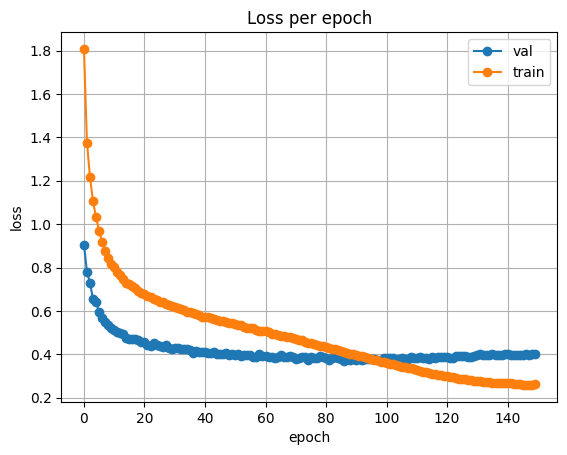

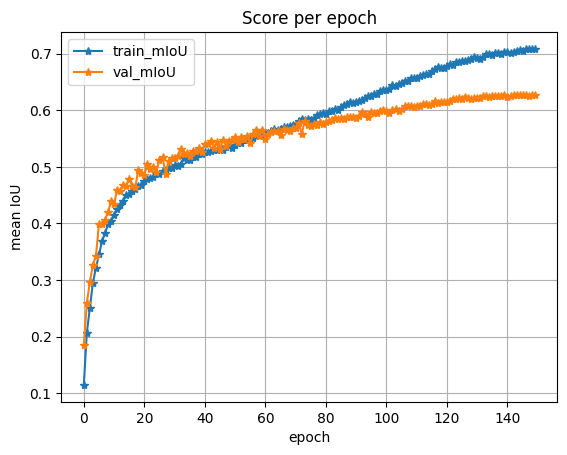

In [30]:
plot_loss(history_sam)
plot_score(history_sam)

## Inference chain: multi-size + flip averaging and small-class suppression, measured on validation

In [31]:
def set_decoder_grid(model: nn.Module, size: int) -> None:
    """Resize the decoder's learned stride-16 positional embedding to the token grid of another input size."""
    decoder = model.decoder
    if not hasattr(decoder, "image_pe_native"):
        decoder.image_pe_native = decoder.image_pe.detach().clone()
    native = decoder.image_pe_native
    grid = int(round(native.shape[1] ** 0.5))
    target = size // 16
    if target == grid:
        pe = native
    else:
        pe = native.view(1, grid, grid, -1).permute(0, 3, 1, 2)
        pe = F.interpolate(pe, size=(target, target), mode="bicubic", align_corners=False)
        pe = pe.permute(0, 2, 3, 1).reshape(1, target * target, -1)
    decoder.image_pe = nn.Parameter(pe.contiguous(), requires_grad=False)


@torch.no_grad()
def predict_probs(model: nn.Module, images: torch.Tensor, sizes: tuple[int, ...], tta: bool) -> torch.Tensor:
    """Softmax averaged over the given input sizes (bilinear resize in, logits resized back) and the horizontal flip."""
    h, w = images.shape[-2:]
    probs = None
    for size in sizes:
        x = images if size == h else F.interpolate(images, size=(size, size), mode="bilinear", align_corners=False)
        set_decoder_grid(model=model, size=size)
        logits = predict_logits(model=model, images=x, tta_hflip=tta)
        if size != h:
            logits = F.interpolate(logits, size=(h, w), mode="bilinear", align_corners=False)
        p = F.softmax(logits, dim=1)
        probs = p if probs is None else probs + p
    set_decoder_grid(model=model, size=CONFIG.img_size)
    return probs / len(sizes)


def suppress_small_classes(probs: torch.Tensor, min_area: int) -> torch.Tensor:
    """Per image, zero the probability of every non-background class predicted on fewer than min_area pixels: a class
    predicted by mistake adds a zero IoU term to that image's mean, so tiny spurious regions cost more than they gain."""
    if min_area <= 0:
        return probs
    probs = probs.clone()
    pred = probs.argmax(dim=1)
    counts = torch.stack([(pred == c).flatten(1).sum(dim=1) for c in range(probs.shape[1])], dim=1)  # (B, C)
    small = (counts > 0) & (counts < min_area)
    small[:, 0] = False
    probs[small.unsqueeze(-1).unsqueeze(-1).expand_as(probs)] = 0.0
    return probs


@torch.no_grad()
def evaluate_chain(model: nn.Module, loader: DataLoader, sizes: tuple[int, ...], min_area: int) -> float:
    """Mean per-image mIoU on validation images given at the competition resolution (ORIG_SIZE)."""
    model.eval()
    mious: list[torch.Tensor] = []
    for images, masks in loader:
        probs = predict_probs(model=model, images=images.to(device, non_blocking=True), sizes=sizes, tta=True)
        probs = suppress_small_classes(probs=probs, min_area=min_area)
        conf = confusion_per_image(pred=probs.argmax(dim=1), target=masks.to(device, non_blocking=True))
        mious.append(miou_from_confusion(conf=conf))
    return torch.cat(mious).mean().item()


model = MiniSAM(cfg=CONFIG).to(device)
model.load_state_dict(torch.load(CKPT_PATH, map_location=device, weights_only=False)["state_dict"])
model.eval()
chain_val_set = CIHPSegDataset(
    image_dir=DATA_DIR / "val",
    mask_dir=DATA_DIR / "val_mask",
    ids=list_ids(folder=DATA_DIR / "val")[:SMOKE_SUBSET],
    transform=None,
    hflip_prob=0.0,
    size=ORIG_SIZE,
    resize_mask=False,
)
chain_loader = DataLoader(dataset=chain_val_set, batch_size=16, shuffle=False, num_workers=4, pin_memory=True)
print(f"val mIoU {CONFIG.img_size} hflip: {evaluate_chain(model=model, loader=chain_loader, sizes=(CONFIG.img_size,), min_area=0):.4f}")
print(f"val mIoU {len(INFER_SIZES)} sizes: {evaluate_chain(model=model, loader=chain_loader, sizes=INFER_SIZES, min_area=0):.4f}")
upload_miou = evaluate_chain(model=model, loader=chain_loader, sizes=INFER_SIZES, min_area=MIN_AREA)
print(f"val mIoU {len(INFER_SIZES)} sizes min-area {MIN_AREA}: {upload_miou:.4f}")
print(f"upload setting (sizes {list(INFER_SIZES)}, hflip, min-area {MIN_AREA}): val mIoU {upload_miou:.4f}")

val mIoU 448 hflip: 0.6337
val mIoU 5 sizes: 0.6501
val mIoU 5 sizes min-area 50: 0.6535
upload setting (sizes [512, 576, 640, 704, 768], hflip, min-area 50): val mIoU 0.6535


### Predict Result

Load the mini-SAM weights of the best validation-mIoU epoch and predict the **course test set** with the inference chain measured above.
Export `output.csv` at the lab root with columns `index,pred_mask`.
Each `pred_mask` is a JSON-compatible nested 320 x 320 list of integers 0--19.
Predict a class at every pixel; the grader ignores pixels using its ground-truth mask.
Row indices must follow `data/test_index.csv`, starting at 0.

The 2026 Kaggle link and public/private split will be announced by the TA.
Do not reuse the 2025 competition link. Run the training section before inference;
this package intentionally contains no trained checkpoint.

In [32]:
TEST_IMAGE_PATH = str(DATA_ROOT / 'test') + os.sep

In [33]:
test_df = create_df(TEST_IMAGE_PATH)
test_index = pd.read_csv(DATA_ROOT / 'test_index.csv')
assert test_index['index'].tolist() == list(range(len(test_df)))
assert test_index['filename'].tolist() == (test_df['id'] + '.png').tolist()

In [34]:
X_test = test_df['id'].to_numpy()

In [35]:
checkpoint = CKPT_PATH  # mini-SAM weights of the best epoch (by val mIoU), written by train_minisam above
if not checkpoint.is_file():
    raise FileNotFoundError(f"Run the mini-SAM training first to create {checkpoint}")
model = MiniSAM(cfg=CONFIG)
model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=False)["state_dict"])
model = model.to(device).eval()

In [36]:
class CIHPTestDataset(Dataset):
    def __init__(self, img_path, X, transform=None):
        self.img_path = img_path
        self.X = X
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        with Image.open(self.img_path + self.X[idx] + '.png') as handle:
            img = np.array(handle.convert('RGB'))
        if self.transform is not None:
            img = self.transform(image=img)['image']
        return Image.fromarray(img)

test_set = CIHPTestDataset(TEST_IMAGE_PATH, X_test)
print(len(test_set))

3961


In [37]:
def predict_image(model, image, mean=MEAN, std=STD):
    """One 320 x 320 PIL image -> (320, 320) class map with the inference chain evaluated above: softmax averaged
    over the INFER_SIZES inputs and their horizontal flips, then classes predicted on fewer than MIN_AREA pixels dropped."""
    model.eval()
    t = T.Compose([T.ToTensor(), T.Normalize(mean, std)])
    image = t(image).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = predict_probs(model=model, images=image, sizes=INFER_SIZES, tta=True)
        probs = suppress_small_classes(probs=probs, min_area=MIN_AREA)
    return probs.argmax(dim=1).cpu().squeeze(0)

In [38]:
import csv
import json

output_path = CSV_DIR / 'output.csv'
with output_path.open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=['index', 'pred_mask'])
    writer.writeheader()
    for i in tqdm(range(len(test_set)), desc='Predict'):
        pred_mask = predict_image(model, test_set[i])
        writer.writerow({'index': i, 'pred_mask': json.dumps(pred_mask.tolist(), separators=(',', ':'))})
print('Saved:', output_path)

Predict: 100%|██████████| 3961/3961 [04:26<00:00, 14.84it/s]

Saved: /content/output.csv


In [39]:
if ON_COLAB:  # keep a copy next to the checkpoints so the CSV survives the session
    shutil.copy(output_path, DRIVE_DIR / "runs" / "output.csv")
    print("Copied to", DRIVE_DIR / "runs" / "output.csv")

Copied to /content/drive/MyDrive/Colab Notebooks/nycu/deep-learning/lab-4-image-segment/runs/output.csv
